Script to automatically align volumetric scape data to a muscle reference map by using the accessory heart muscles.

Requires first manually labelled the accessory heart muscles in the scape video. Note: do this when the muscle is lit up but not when it is contracted, as it distorts its shape.

Steps:
- Load manual rois 
- Load max projection for matching data
- asign manual rois an identity (RF, LF, etc.) - remember right is on left when looking at legs
- Load reference labels (for acc-heart-muscles but also all selected muscles)
- get centroid of both manual and referece
- scale, rotate and shift reference to match manual - how does it look? Compare selected muscles to max projection
- if not great, try stretching

### Load all relevant data

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import distance

from scape_utils import load_napari_rois, load_voxel_size, load_aspect_ratio_YX, load_proj
%matplotlib inline

import sys
sys.path.append(str(Path('/home/azcorra/git/Devel/Pupa_muscle_imaging/referenceMaps')))
from webknossos import load_labels

In [2]:
# set paths to data and reference map labels:
main_path = Path('/mnt/labserver/data/MA/SCAPE/')
scape_path = main_path / '20260716_MA12_pupa-P15/sample2_run2'
acc_heart_path = scape_path / 'accessory_heart_muscles_rois.nrrd'

reference_path = Path('/mnt/labserver/data/MA/CT_scans_PIXE/2026-06-16_Webknossos_muscle_leg_tracing_pupa_annotations/RF-RM Leg muscles in pupa')
labels_path = reference_path / 'labels'
selected_path = reference_path / 'meshes_selected'

In [3]:
# Get projection image for scape data (and aspect_ratio for plotting)
proj = load_proj(scape_path, 'max_proj')
voxel_sizes = load_voxel_size(scape_path)
axes_order = list(voxel_sizes.keys())

aspect_ratio = [
    voxel_sizes[others[0]] / voxel_sizes[others[1]]
    for i, element in enumerate(axes_order)
    for others in [axes_order[:i] + axes_order[i+1:]]
]

In [4]:
# Load manual rois for accessory heart muscles (labels)
acc_heart_manual = load_napari_rois(acc_heart_path)
acc_heart_manual_id = {'RM': 1, 'RF': 2, 'LF': 3, 'LM': 4}

In [5]:
# Load reference labels
labels, id_to_name = load_labels(labels_path) # takes about 1 min
# webknossos labels are indexed (x,y,z); reorder to match manual (z,y,x) axes
# (must reverse axis order, not permute (1,2,0) which gives (y,z,x)):
labels = np.transpose(labels, (2, 1, 0))
# two axes are inverted (point reflection) - so reverse
labels = labels[::-1, ::-1, :]

# select accessory heart muscles
acc_heart_ref_id = {name[:2]: id for id, name in id_to_name.items() if 'heart' in name and 'p1' in name}
# find the selected muscles (all files in the selected_path folder)
stl_list = list(selected_path.glob('*.stl'))
selected_muscles = {k: v for k, v in (p.stem.rsplit('-', 1) for p in stl_list)}

### Align centroids

In [6]:
# get centroids for each accessory heart muscle in the reference and manual rois
centroids_manual = {}
centroids_ref = {}

for leg, id in acc_heart_manual_id.items():

    # manual centroids
    mask_manual = acc_heart_manual == id
    coords_manual = np.argwhere(mask_manual)
    centroids_manual[leg] = coords_manual.mean(axis=0)

    # correct manual centroids for aspect ratio
    centroids_manual[leg] = centroids_manual[leg] * list(voxel_sizes[ax] for ax in axes_order)

    # reference centroids
    ref_id = acc_heart_ref_id[leg]
    mask_ref = labels == ref_id
    coords_ref = np.argwhere(mask_ref)
    centroids_ref[leg] = coords_ref.mean(axis=0)

    del mask_manual, coords_manual, mask_ref, coords_ref


### Fit similarity transform

In [7]:
def fit_similarity_transform(source_points, target_points):
    """
    Fits a rigid + uniform scale transform mapping source points onto
    target points, using Umeyama's closed-form least-squares algorithm.

    Solves for the rotation `R`, scale `s`, and translation `t` that
    minimize `sum(||s * R @ source_i + t - target_i||**2)` over all
    corresponding point pairs. Points must already be in correspondence
    (`source_points[i]` matches `target_points[i]`).

    Parameters
    ----------
    source_points : (N, 3) array
        Points to be transformed (here: reference centroids).

    target_points : (N, 3) array
        Points to align to (here: manual centroids, in physical units).

    Returns
    -------
    R : (3, 3) array
        Rotation matrix.

    scale : float
        Uniform scale factor.

    t : (3,) array
        Translation vector.
    """
    source = np.asarray(source_points, dtype=float)
    target = np.asarray(target_points, dtype=float)
    n_points = source.shape[0]

    mean_source = source.mean(axis=0)
    mean_target = target.mean(axis=0)
    source_centered = source - mean_source
    target_centered = target - mean_target

    covariance = (target_centered.T @ source_centered) / n_points
    U, singular_values, Vt = np.linalg.svd(covariance)

    S = np.eye(3)
    if np.linalg.det(U) * np.linalg.det(Vt) < 0:
        S[-1, -1] = -1

    R = U @ S @ Vt
    source_variance = np.sum(source_centered ** 2) / n_points
    scale = np.sum(singular_values * np.diag(S)) / source_variance
    t = mean_target - scale * (R @ mean_source)

    return R, scale, t

In [8]:
def build_homogeneous_transform(R, scale, t):
    """
    Assembles a rotation, scale, and translation into a 4x4 homogeneous
    transform mapping `x` to `scale * R @ x + t`.

    Parameters
    ----------
    R : (3, 3) array
        Rotation matrix.

    scale : float
        Uniform scale factor.

    t : (3,) array
        Translation vector.

    Returns
    -------
    (4, 4) array
        Homogeneous transform matrix.
    """
    T = np.eye(4)
    T[:3, :3] = scale * R
    T[:3, 3] = t
    return T

In [9]:
# fixed correspondence order so the reference/manual point arrays line up
# by leg identity, not by dict iteration order
leg_order = ['RM', 'RF', 'LF', 'LM']
ref_points = np.array([centroids_ref[leg] for leg in leg_order])
manual_points = np.array([centroids_manual[leg] for leg in leg_order])

R, scale, t = fit_similarity_transform(ref_points, manual_points)
T_forward = build_homogeneous_transform(R, scale, t)

ref_points_aligned = {
    leg: scale * (R @ centroids_ref[leg]) + t for leg in leg_order
}
residuals = {
    leg: np.linalg.norm(ref_points_aligned[leg] - centroids_manual[leg])
    for leg in leg_order
}

print(f'Fitted scale (reference voxel units -> manual physical units): {scale:.4f}')
print(f'Per-landmark residual after fit (µm): {residuals}')

for leg_a, leg_b in [('RF', 'LF'), ('RM', 'LM')]:
    dist_manual = np.linalg.norm(centroids_manual[leg_a] - centroids_manual[leg_b])
    dist_aligned = np.linalg.norm(ref_points_aligned[leg_a] - ref_points_aligned[leg_b])
    print(f'{leg_a}-{leg_b} distance (µm) — manual: {dist_manual:.2f}, aligned reference: {dist_aligned:.2f}')

Fitted scale (reference voxel units -> manual physical units): 0.5965
Per-landmark residual after fit (µm): {'RM': np.float64(26.357537641564434), 'RF': np.float64(20.258463999958323), 'LF': np.float64(16.104805887585663), 'LM': np.float64(24.4765041519713)}
RF-LF distance (µm) — manual: 562.00, aligned reference: 567.03
RM-LM distance (µm) — manual: 572.65, aligned reference: 537.83


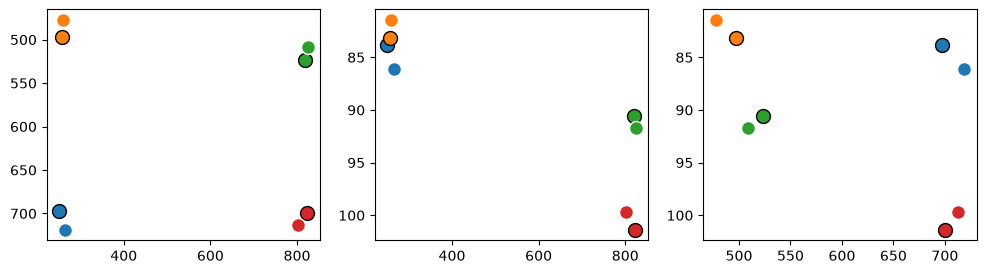

In [10]:
# QC: black-outlined = manual, white-outlined = fitted reference; same
# color = same leg identity. Overlapping same-colored pairs indicate a
# good fit.
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
fig, axs = plt.subplots(1, 3, figsize=[12, 3])
for ax_idx, ax_plot in enumerate(axs):
    axes = [n for n in [0, 1, 2] if n != ax_idx]
    for i, leg in enumerate(leg_order):
        manual_centroid = manual_points[i]
        aligned_centroid = ref_points_aligned[leg]
        ax_plot.plot(manual_centroid[axes[1]], manual_centroid[axes[0]], 'o', ms=10, mec='k', mfc=colors[i])
        ax_plot.plot(aligned_centroid[axes[1]], aligned_centroid[axes[0]], 'o', ms=10, mec='w', mfc=colors[i])
    ax_plot.invert_yaxis()
plt.show()

### Warp reference volume onto manual grid

In [ ]:
from scipy.ndimage import affine_transform


def warp_labels_to_manual_grid(source_volume, T_forward, target_shape,
                                source_voxel_size=(1.0, 1.0, 1.0),
                                target_voxel_size=(1.0, 1.0, 1.0)):
    """
    Resamples a labeled voxel volume onto a differently-spaced target grid,
    using a rigid + uniform scale transform fit on physical-space points.

    All coordinates and voxel sizes are in array-axis order (matching
    `source_volume`'s and `target_shape`'s own axis order, e.g. (z, y, x)) —
    since `T_forward` was fit directly on `np.argwhere`-derived centroids in
    that same order, no physical (x, y, z) <-> array-index permutation is
    needed here.

    Parameters
    ----------
    source_volume : ndarray
        Labeled array to resample from (e.g. the reference `labels`
        volume).

    T_forward : (4, 4) array
        Homogeneous transform mapping source physical coordinates to
        target physical coordinates (see `build_homogeneous_transform`).

    target_shape : tuple of int
        Output array shape, matching the target grid (e.g.
        `acc_heart_manual.shape`).

    source_voxel_size : tuple of float
        Physical size per voxel of `source_volume`, one value per axis.

    target_voxel_size : tuple of float
        Physical size per voxel of the output grid, one value per axis.

    Returns
    -------
    ndarray
        `source_volume` resampled onto the target grid, with label IDs
        preserved via nearest-neighbor interpolation.
    """
    S_source = np.diag([*source_voxel_size, 1.0])
    S_target = np.diag([*target_voxel_size, 1.0])

    # maps target voxel indices to source voxel indices (pull mapping,
    # as required by affine_transform)
    T_voxel = np.linalg.inv(S_source) @ np.linalg.inv(T_forward) @ S_target

    return affine_transform(
        source_volume,
        matrix=T_voxel[:3, :3],
        offset=T_voxel[:3, 3],
        output_shape=target_shape,
        order=0,
        mode='constant',
        cval=0,
    )

In [ ]:
target_voxel_size = tuple(voxel_sizes[ax] for ax in axes_order)

labels_aligned = warp_labels_to_manual_grid(
    labels, T_forward,
    target_shape=acc_heart_manual.shape,
    source_voxel_size=(1.0, 1.0, 1.0),
    target_voxel_size=target_voxel_size,
)

print('Reference non-zero voxels:', np.count_nonzero(labels))
print('Aligned non-zero voxels:', np.count_nonzero(labels_aligned))
print('Unique labels preserved:', np.unique(labels_aligned))

### Visual QC: compare aligned reference to SCAPE data

In [ ]:
# relabel the aligned reference's heart-muscle IDs to match acc_heart_manual_id,
# so the two overlays share the same color mapping
ax_proj = 0  # project along z, matching how proj/acc_heart_manual are viewed above

proj_flat = np.max(proj, axis=ax_proj)

acc_heart_aligned = np.zeros_like(labels_aligned, dtype=np.uint8)
for leg, ref_id in acc_heart_ref_id.items():
    acc_heart_aligned[labels_aligned == ref_id] = acc_heart_manual_id[leg]

fig, axs = plt.subplots(1, 2, figsize=[12, 6])
for ax_plot, volume, title in zip(
    axs, (acc_heart_manual, acc_heart_aligned), ('Manual ROIs', 'Aligned reference')
):
    ax_plot.imshow(proj_flat, aspect=aspect_ratio[ax_proj], cmap='gray', vmax=800)
    overlay = np.ma.masked_equal(np.max(volume, axis=ax_proj), 0)
    ax_plot.imshow(overlay, aspect=aspect_ratio[ax_proj], cmap='tab10', alpha=0.5, vmin=1, vmax=4)
    ax_plot.set_title(title)

In [ ]:
# broader sanity check: do all the selected leg muscles (not just the
# heart-muscle landmarks used to fit the transform) look anatomically
# plausible against the SCAPE projection?
selected_ids = {int(muscle_id) for muscle_id in selected_muscles.values()}
selected_mask = np.isin(labels_aligned, list(selected_ids))

plt.figure(figsize=[6, 6])
plt.imshow(proj_flat, aspect=aspect_ratio[ax_proj], cmap='gray', vmax=800)
overlay = np.ma.masked_equal(np.max(selected_mask, axis=ax_proj), 0)
plt.imshow(overlay, aspect=aspect_ratio[ax_proj], cmap='autumn', alpha=0.4)
plt.title('All selected muscles, aligned reference')

### Align two scape volumes by correlation

In [ ]:
# set paths to data and reference map labels:
main_path = Path('/mnt/labserver/data/MA/SCAPE/')
scape_path_1 = main_path / '20260716_MA12_pupa-P15/sample4_run2'
scape_path_2 = main_path / '20260716_MA12_pupa-P15/sample3_run3'

# Get projection images for scape data
proj_1 = load_proj(scape_path_1, 'max_proj')
proj_2 = load_proj(scape_path_2, 'max_proj')

proj_1 = np.log1p(proj_1)
proj_2 = np.log1p(proj_2)

In [ ]:
# Get voxel sizes for both recordings (needed for physically-aware
# registration, since z/x/y spacing is anisotropic)
voxel_sizes_1 = load_voxel_size(scape_path_1)
voxel_sizes_2 = load_voxel_size(scape_path_2)
axes_order = list(voxel_sizes_1.keys())  # (z, x, y), matching proj_1/proj_2's array axes

print(f'proj_1 shape: {proj_1.shape}, voxel sizes ({axes_order}): {voxel_sizes_1}')
print(f'proj_2 shape: {proj_2.shape}, voxel sizes ({axes_order}): {voxel_sizes_2}')

Non-rigid alignment of `proj_2` onto `proj_1`, using correlation to drive both a rigid pre-alignment and a deformable refinement:

1. Zero-pad both volumes (centered) to a common shape, since the two runs have slightly different extents.
2. Estimate a global rigid (translation) shift by phase cross-correlation, and pre-shift `proj_2` onto `proj_1`'s grid.
3. Refine with a multi-resolution Demons deformable registration (SimpleITK), giving a dense displacement field.
4. QC: compare `proj_1` to `proj_2` before/after each step, both visually and by normalized cross-correlation.

On the `sample2_run2`/`sample3_run3` pair (336, 269, 1000) this takes about 3 minutes total (~6s for step 2, ~165s for step 3, dominated by the full-resolution pyramid level), and raised the NCC from 0.84 (raw) to 0.87 (after the global shift) to 0.95 (after Demons). If a different pair is much larger, increase `shrink_factors`/`smoothing_sigmas` in the Demons cell below to add a coarser starting level.

In [ ]:
def pad_to_common_shape(volume_1: np.ndarray, volume_2: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """
    Zero-pads two volumes, centered, so they share a common shape.

    Parameters
    ----------
    volume_1 : ndarray
        First volume.

    volume_2 : ndarray
        Second volume, with the same number of dimensions as `volume_1`.

    Returns
    -------
    tuple of ndarray
        `volume_1` and `volume_2`, each zero-padded to
        `np.maximum(volume_1.shape, volume_2.shape)`.
    """
    target_shape = [max(size_1, size_2) for size_1, size_2 in zip(volume_1.shape, volume_2.shape)]

    def pad(volume):
        pad_widths = []
        for size, target in zip(volume.shape, target_shape):
            before = (target - size) // 2
            after = target - size - before
            pad_widths.append((before, after))
        return np.pad(volume, pad_widths, mode='constant', constant_values=0)

    return pad(volume_1), pad(volume_2)


proj_1_pad, proj_2_pad = pad_to_common_shape(proj_1, proj_2)
print(f'proj_1 shape: {proj_1.shape} -> padded: {proj_1_pad.shape}')
print(f'proj_2 shape: {proj_2.shape} -> padded: {proj_2_pad.shape}')

### Global rigid pre-alignment (phase cross-correlation)

In [ ]:
from skimage.registration import phase_cross_correlation
from scipy.ndimage import shift as ndi_shift

# unnormalized cross-correlation (normalization=None), since the default
# phase-only normalization is dominated by the sharp edges introduced by
# the zero-padding above and gives a spurious shift; float64 avoids a
# float32 overflow in skimage's internal error-confidence computation
global_shift, error, _ = phase_cross_correlation(
    proj_1_pad.astype(np.float64), proj_2_pad.astype(np.float64),
    upsample_factor=10, normalization=None,
)
print(f'Estimated global shift (voxels, {axes_order}): {global_shift}, correlation error: {error:.4f}')

proj_2_prealigned = ndi_shift(proj_2_pad, shift=global_shift, order=1, mode='constant', cval=0)

### Deformable refinement (multi-resolution Demons)

In [ ]:
import SimpleITK as sitk


def smooth_and_resample(image: sitk.Image, shrink_factor: float, smoothing_sigma: float) -> sitk.Image:
    """
    Smooths and downsamples a SimpleITK image, for building a
    resolution pyramid.

    Parameters
    ----------
    image : sitk.Image
        Image to smooth and downsample.

    shrink_factor : float
        Factor by which to shrink each dimension (1.0 leaves the size
        unchanged).

    smoothing_sigma : float
        Gaussian smoothing sigma, in physical units. 0 disables
        smoothing.

    Returns
    -------
    sitk.Image
        Smoothed, resampled image.
    """
    smoothed = sitk.SmoothingRecursiveGaussian(image, smoothing_sigma) if smoothing_sigma > 0 else image

    original_size = image.GetSize()
    original_spacing = image.GetSpacing()
    new_size = [int(size / float(shrink_factor) + 0.5) for size in original_size]
    new_spacing = [
        ((old_size - 1) * old_spacing) / (new_size_i - 1)
        for old_size, old_spacing, new_size_i in zip(original_size, original_spacing, new_size)
    ]
    return sitk.Resample(
        smoothed, new_size, sitk.Transform(), sitk.sitkLinear,
        image.GetOrigin(), new_spacing, image.GetDirection(), 0.0, image.GetPixelID(),
    )


def multiscale_demons(registration_filter, fixed_image: sitk.Image, moving_image: sitk.Image,
                       shrink_factors: list, smoothing_sigmas: list) -> sitk.Image:
    """
    Runs a SimpleITK Demons-family registration filter over a Gaussian
    resolution pyramid, upsampling the displacement field between
    levels. This SimpleITK build does not wrap
    `MultiResolutionPDEDeformableRegistration`, so the pyramid is built
    by hand here (standard approach from the SimpleITK Demons
    registration example notebooks).

    Parameters
    ----------
    registration_filter : sitk.PDEDeformableRegistrationFilter
        Configured Demons-family registration filter (e.g. an
        `sitk.DemonsRegistrationFilter` instance).

    fixed_image : sitk.Image
        Image to register to (here: `proj_1` as a `sitk.Image`).

    moving_image : sitk.Image
        Image to be warped (here: `proj_2_prealigned` as a
        `sitk.Image`).

    shrink_factors : list of float
        Per-level shrink factors; must line up with `smoothing_sigmas`.
        The last entry should be 1.0 for a full-resolution final level.

    smoothing_sigmas : list of float
        Per-level Gaussian smoothing sigma (physical units), matched to
        `shrink_factors`.

    Returns
    -------
    sitk.Image
        Dense displacement field (`sitkVectorFloat64`), at
        `fixed_image`'s full resolution.
    """
    fixed_images = [fixed_image]
    moving_images = [moving_image]
    for shrink_factor, smoothing_sigma in reversed(list(zip(shrink_factors, smoothing_sigmas))):
        fixed_images.append(smooth_and_resample(fixed_images[0], shrink_factor, smoothing_sigma))
        moving_images.append(smooth_and_resample(moving_images[0], shrink_factor, smoothing_sigma))

    displacement_field = sitk.Image(fixed_images[-1].GetSize(), sitk.sitkVectorFloat64)
    displacement_field.CopyInformation(fixed_images[-1])
    displacement_field = registration_filter.Execute(fixed_images[-1], moving_images[-1], displacement_field)

    for f_image, m_image in reversed(list(zip(fixed_images[:-1], moving_images[:-1]))):
        displacement_field = sitk.Resample(displacement_field, f_image)
        displacement_field = registration_filter.Execute(f_image, m_image, displacement_field)

    return displacement_field

In [ ]:
# proj_1/proj_2's array axes are (z, x, y) (see axes_order above);
# SimpleITK expects size/spacing in the reverse order
spacing_1 = tuple(voxel_sizes_1[ax] for ax in axes_order)[::-1]
spacing_2 = tuple(voxel_sizes_2[ax] for ax in axes_order)[::-1]

fixed_image = sitk.GetImageFromArray(proj_1_pad.astype(np.float32))
fixed_image.SetSpacing(spacing_1)
moving_image = sitk.GetImageFromArray(proj_2_prealigned.astype(np.float32))
moving_image.SetSpacing(spacing_2)

demons_filter = sitk.DemonsRegistrationFilter()
demons_filter.SetNumberOfIterations(50)
demons_filter.SetStandardDeviations(1.0)  # regularizes (smooths) the displacement field

# coarser levels only: fixed_image/moving_image themselves already serve
# as the finest (full-resolution) pyramid level inside multiscale_demons
displacement_field = multiscale_demons(
    demons_filter, fixed_image, moving_image,
    shrink_factors=[4, 2], smoothing_sigmas=[4, 2],
)

transform = sitk.DisplacementFieldTransform(displacement_field)
resampler = sitk.ResampleImageFilter()
resampler.SetReferenceImage(fixed_image)
resampler.SetInterpolator(sitk.sitkLinear)
resampler.SetTransform(transform)
proj_2_registered = sitk.GetArrayFromImage(resampler.Execute(moving_image))

### Visual QC: compare proj_1 to proj_2 before/after each step

In [ ]:
def red_green_overlay(red_volume: np.ndarray, green_volume: np.ndarray,
                       vmin: float = 0, vmax: float = None) -> np.ndarray:
    """
    Builds an RGB image with `red_volume` in the red channel and
    `green_volume` in the green channel, for visually checking spatial
    overlap (well-aligned structures appear yellow).

    Parameters
    ----------
    red_volume : ndarray
        2D image for the red channel (e.g. a max-z projection of
        `proj_1_pad`).

    green_volume : ndarray
        2D image for the green channel, same shape as `red_volume`.

    vmin : float
        Intensity mapped to zero channel brightness, for both
        channels.

    vmax : float or None
        Intensity mapped to full channel brightness. If None (default),
        each channel is normalized independently, using its own 99.9th
        percentile — needed when the two inputs are on very different
        scales (e.g. raw counts vs. `log1p`-compressed, or two
        different modalities entirely). Pass an explicit value to use
        the same scale for both channels instead.

    Returns
    -------
    ndarray
        RGB image of shape `(*red_volume.shape, 3)`, float in [0, 1].
    """
    red_vmax = np.percentile(red_volume, 99.9) if vmax is None else vmax
    green_vmax = np.percentile(green_volume, 99.9) if vmax is None else vmax

    rgb = np.zeros((*red_volume.shape, 3))
    rgb[..., 0] = np.clip((red_volume - vmin) / (red_vmax - vmin), 0, 1)
    rgb[..., 1] = np.clip((green_volume - vmin) / (green_vmax - vmin), 0, 1)
    return rgb

ax_proj=0
proj_1_pad_flat = np.max(proj_1_pad, axis=ax_proj)

fig, axs = plt.subplots(1, 3, figsize=[15, 5])
for ax_plot, volume, title in zip(
    axs, (proj_2_pad, proj_2_prealigned, proj_2_registered),
    ('original', 'global shift', 'demons registered'),
):
    overlay = red_green_overlay(proj_1_pad_flat, np.max(volume, axis=ax_proj), vmin=4.5, vmax=7)
    ax_plot.imshow(overlay, aspect=aspect_ratio[ax_proj])
    ax_plot.set_title(f'proj_1 (red) / proj_2 (green): {title}')

# Keep only one hemibody

In [ ]:
from scipy.optimize import minimize
from scipy.ndimage import zoom


def build_reflection_transform(theta_1: float, theta_2: float, offset_axis2: float,
                                shape: tuple) -> tuple:
    """
    Builds the affine (matrix, offset) pair that reflects a volume
    across a mirror-symmetry plane whose normal is close to axis 2,
    tilted by `theta_1` towards axis 0 and `theta_2` towards axis 1.

    Parameters
    ----------
    theta_1 : float
        Small angle (radians) tilting the plane's normal towards axis
        0.

    theta_2 : float
        Small angle (radians) tilting the plane's normal towards axis
        1.

    offset_axis2 : float
        Position, along axis 2, where the plane crosses the volume's
        axis-0/axis-1 center line.

    shape : tuple of int
        Shape of the volume to be reflected.

    Returns
    -------
    tuple of ndarray
        `(matrix, offset)`, the linear part and offset of the affine
        reflection, usable directly with
        `scipy.ndimage.affine_transform` (a reflection is its own
        inverse, so no separate forward/pull mapping is needed).
    """
    normal = np.array([np.sin(theta_1), np.sin(theta_2), 1.0])
    normal /= np.linalg.norm(normal)

    point_on_plane = np.array([(shape[0] - 1) / 2, (shape[1] - 1) / 2, offset_axis2])
    matrix = np.eye(3) - 2 * np.outer(normal, normal)
    offset = point_on_plane - matrix @ point_on_plane
    return matrix, offset


def mirror_volume(volume: np.ndarray, theta_1: float, theta_2: float, offset_axis2: float,
                   cval: float = 0.0) -> np.ndarray:
    """
    Reflects `volume` across the plane defined by `theta_1`, `theta_2`,
    and `offset_axis2` (see `build_reflection_transform`).

    Parameters
    ----------
    volume : ndarray
        Volume to reflect.

    theta_1 : float
        See `build_reflection_transform`.

    theta_2 : float
        See `build_reflection_transform`.

    offset_axis2 : float
        See `build_reflection_transform`.

    cval : float
        Fill value for voxels whose reflection falls outside the
        volume. Use `np.nan` to mark them for exclusion (e.g. when
        scoring symmetry), or `0.0` for display.

    Returns
    -------
    ndarray
        `volume`, reflected across the plane.
    """
    matrix, offset = build_reflection_transform(theta_1, theta_2, offset_axis2, volume.shape)
    return affine_transform(volume, matrix=matrix, offset=offset, order=1, mode='constant', cval=cval)


def symmetry_plane_objective(params: np.ndarray, volume: np.ndarray) -> float:
    """
    Negative normalized cross-correlation between `volume` and its
    reflection across the candidate plane in `params`, for use with
    `scipy.optimize.minimize` (voxels whose reflection falls outside
    the volume are excluded, rather than treated as zero).

    Parameters
    ----------
    params : ndarray
        `(theta_1, theta_2, offset_axis2)` — see
        `build_reflection_transform`.

    volume : ndarray
        Volume being fit.

    Returns
    -------
    float
        Negative NCC between `volume` and its reflection (0 if no
        voxels overlap).
    """
    theta_1, theta_2, offset_axis2 = params
    mirrored = mirror_volume(volume, theta_1, theta_2, offset_axis2, cval=np.nan)
    valid = ~np.isnan(mirrored)
    if not np.any(valid):
        return 0.0

    a = volume[valid] - volume[valid].mean()
    b = mirrored[valid] - mirrored[valid].mean()
    denom = np.sqrt((a ** 2).sum() * (b ** 2).sum())
    return -float((a * b).sum() / denom) if denom > 0 else 0.0


def fit_symmetry_plane(volume: np.ndarray, downsample_factor: float = 0.2) -> np.ndarray:
    """
    Fits the mirror-symmetry plane of `volume` by maximizing the
    correlation between the volume and its own reflection, starting
    from a plane parallel to the axis-0/axis-1 plane through the
    volume's axis-2 midpoint.

    The optimization runs on a downsampled copy for speed (at full
    resolution, on a (336, 269, 1000) volume, this optimization takes
    about 15 minutes; downsampled to `downsample_factor=0.2` it takes
    about 6 seconds and gives the same plane to within ~1 full-resolution
    voxel), then rescales `offset_axis2` back to `volume`'s own
    resolution (`theta_1`/`theta_2` are scale-invariant angles, so they
    need no rescaling).

    Parameters
    ----------
    volume : ndarray
        Volume to fit (e.g. `proj_1_pad`).

    downsample_factor : float
        Factor used to shrink `volume` before fitting (see above). Use
        `1.0` to fit at full resolution instead.

    Returns
    -------
    ndarray
        `(theta_1, theta_2, offset_axis2)` of the fitted plane, in
        `volume`'s own (full-resolution) voxel coordinates (see
        `build_reflection_transform`).
    """
    fit_volume = zoom(volume, downsample_factor, order=1) if downsample_factor != 1.0 else volume

    initial_guess = [0.0, 0.0, fit_volume.shape[2] / 2]
    result = minimize(symmetry_plane_objective, initial_guess, args=(fit_volume,), method='Nelder-Mead')
    theta_1, theta_2, offset_axis2 = result.x
    offset_axis2 /= downsample_factor  # back to volume's own voxel coordinates

    print(f'Fitted midplane: tilt to axis 0 = {np.degrees(theta_1):.2f} deg, '
          f'tilt to axis 1 = {np.degrees(theta_2):.2f} deg, '
          f'offset along axis 2 = {offset_axis2:.1f}, NCC = {-result.fun:.4f}')
    return np.array([theta_1, theta_2, offset_axis2])


def keep_one_hemibody(volume: np.ndarray, offset_axis2: float, side: int = 1) -> np.ndarray:
    """
    Crops `volume` to one side of the fitted mirror-symmetry plane
    along axis 2, roughly halving its size.

    Uses a hard crop (not a tilted-plane mask) since the fitted tilt
    is negligible in practice (<0.01 degree on this data — see
    `fit_symmetry_plane`), so the plane is effectively exactly
    perpendicular to axis 2.

    Parameters
    ----------
    volume : ndarray
        Volume to crop.

    offset_axis2 : float
        Axis-2 position of the plane (see `build_reflection_transform`).

    side : 1 or -1
        Which side of the plane to keep (`1`: axis-2 index >=
        `offset_axis2`; `-1`: below it). Flip the sign if the wrong
        hemibody comes out.

    Returns
    -------
    ndarray
        `volume`, cropped to one side of the plane along axis 2.
    """
    split_index = int(round(offset_axis2))
    return volume[:, :, split_index:] if side == 1 else volume[:, :, :split_index]

In [ ]:
theta_1, theta_2, offset_axis2 = fit_symmetry_plane(proj_1_pad)

proj_1_mirrored = mirror_volume(proj_1_pad, theta_1, theta_2, offset_axis2)

# QC: red = proj_1, green = proj_1 reflected across the fitted plane;
# well-aligned (yellow) structures confirm the plane is correct
ax_proj = 0  # project along z, consistent with the rest of this notebook
overlay = red_green_overlay(np.max(proj_1_pad, axis=ax_proj), np.max(proj_1_mirrored, axis=ax_proj), vmin=4.5)

plt.figure(figsize=[6, 6])
plt.imshow(overlay, aspect=aspect_ratio[ax_proj])
plt.axvline(offset_axis2, color='w', ls='--', lw=1)  # axis 2 maps to the image's x-axis here
plt.title('proj_1 (red) / proj_1 mirrored (green)')

In [ ]:
# side=1/-1 picks which hemibody survives; flip it if the wrong one is kept
side = -1
proj_1_hemibody = keep_one_hemibody(proj_1_pad, offset_axis2, side=side)
print(f'proj_1_pad shape: {proj_1_pad.shape} -> hemibody: {proj_1_hemibody.shape}')

fig, axs = plt.subplots(1, 2, figsize=[10, 5])
axs[0].imshow(np.max(proj_1_pad, axis=ax_proj), aspect=aspect_ratio[ax_proj], vmin=4.5)
axs[0].axvline(offset_axis2, color='w', ls='--', lw=1)
axs[0].set_title('proj_1 (both hemibodies)')
axs[1].imshow(np.max(proj_1_hemibody, axis=ax_proj), aspect=aspect_ratio[ax_proj], vmin=4.5)
axs[1].set_title(f'proj_1 (side={side})')

## Save pre-aligned labels to napari-compatible labels, segment by segment

In [11]:
import nrrd
import json
from webknossos import load_segment_groups

# Single whole-volume save (no per-segment copies, which is what
# crashed the kernel) — segment selection happens later, on demand, in
# the napari script, using the id -> name/group matching file saved
# alongside it. T_forward is saved too, as the initial rigid+scale
# alignment for that script to start manual refinement from.
leg_ids = ('RF', 'RM', 'LF', 'LM')
segments = ('coxa', 'trochanter', 'femur', 'tibia')
segment_groups = load_segment_groups(labels_path, leg_ids, segments)

analysis_path = scape_path / 'analysis'
analysis_path.mkdir(exist_ok=True)

# nrrd files are (x, y, z); `labels` is (z, y, x) here (see the
# load_labels cell above), matching how load_napari_rois reads nrrd
# back with the inverse transpose
nrrd.write(str(analysis_path / 'pre-aligned_labels.nrrd'), np.transpose(labels, (2, 1, 0)))

with open(analysis_path / 'pre-aligned_labels_ids.json', 'w') as f:
    json.dump({'id_to_name': {str(k): v for k, v in id_to_name.items()},
               'id_to_group': {str(k): v for k, v in segment_groups.items()},
               'T_forward': T_forward.tolist()}, f, indent=2)

print(f'Saved pre-aligned_labels.nrrd {labels.shape} and pre-aligned_labels_ids.json '
      f'({len(id_to_name)} named ids, {len(segment_groups)} grouped into '
      f'{len(set(segment_groups.values()))} leg segments)')

Saved pre-aligned_labels.nrrd (1120, 1184, 1312) and pre-aligned_labels_ids.json (98 named ids, 61 grouped into 10 leg segments)
